In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import copy
import itertools
import networkx as nx
import random
from collections import defaultdict
import matplotlib.pyplot as plt
import multiprocessing
from functools import partial
import seaborn as sns
from itertools import combinations
from scipy import stats

In [2]:
plos_path = "/u/miaoli/ember_home/dropbox/contribution/contributioncredit_au_pub_country.csv"

In [3]:
sheet1 = pd.read_excel(plos_path, sheet_name="widget (70)",
                      names=['status','doi','author_cnt','journal','credit','name','author_order','gender','author_role','nan1','nan2'])
sheet1 = sheet1.drop(columns=['nan1','nan2'])

In [4]:
sheet1.head()

,status,doi,author_cnt,journal,credit,name,author_order,gender,author_role
0,In WOS,10.1371/journal.pbio.1002611,1.0,PLOS Biology,Conceptualization,Peter Neri,1.0,M,First
1,In WOS,10.1371/journal.pbio.1002611,1.0,PLOS Biology,Data curation,Peter Neri,1.0,M,First
2,In WOS,10.1371/journal.pbio.1002611,1.0,PLOS Biology,Formal analysis,Peter Neri,1.0,M,First
3,In WOS,10.1371/journal.pbio.1002611,1.0,PLOS Biology,Funding acquisition,Peter Neri,1.0,M,First
4,In WOS,10.1371/journal.pbio.1002611,1.0,PLOS Biology,Investigation,Peter Neri,1.0,M,First


### remove duplicated rows (doi, author_order,credit)

In [5]:
sheet1 = sheet1.drop_duplicates(subset=['doi','author_order','credit'])

In [6]:
plos_ostbk_path = '../../data/dropbox/LaborDivision/data/PloS-credit/plos_ostbk.txt'

In [7]:
plos_ostbk = pd.read_csv(plos_ostbk_path, sep=",",names=['ost_bk','doi'],header=1)
plos_ostbk.head()

,ost_bk,doi
0,66915750.0,10.1371/journal.pone.0189230
1,78127338.0,10.1371/journal.pone.0180085
2,89807970.0,10.1371/journal.pone.0184826
3,66945811.0,10.1371/journal.pone.0206368
4,89817326.0,10.1371/journal.pgen.1007027


In [8]:
plos_ostbk[plos_ostbk.ost_bk==93127179]

,ost_bk,doi
787,93127179.0,10.1371/journal.pone.0191669


In [9]:
sheet1.credit.unique()

array(['Conceptualization', 'Data curation', 'Formal analysis',
       'Funding acquisition', 'Investigation', 'Methodology',
       'Project administration', 'Resources', 'Software', 'Supervision',
       'Validation', 'Visualization', 'Writing - Original Draft',
       'Writing - Review & Editing'], dtype=object)

In [10]:
data = plos_ostbk.merge(sheet1.drop(columns=['status','author_cnt','journal','gender','author_role']),
                        on='doi',
                       how='inner')
total_plos = data['doi'].nunique() #total number of articles in plos dataset
data = data.drop(columns=['doi'])

In [11]:
all_df = pd.read_csv("../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv")

### remove duplicated rows in all_df (this part will be cleaned in compile stage)

In [12]:
all_df = all_df.drop_duplicates(subset=['ost_bk','cluster_id'])

### remove publications where ost_bk and author_order is nan

In [13]:
invalid_id = data[data.ost_bk.isna()|data.author_order.isna()]['ost_bk'].unique()
data = data[~data.ost_bk.isin(invalid_id)]
print("number of papers are removed %s which is %s of total papers."%(len(invalid_id),len(invalid_id)/total_plos))

number of papers are removed 1394 which is 0.04530533979004842 of total papers.


### merge plos data with the author information data

In [14]:
data = data.merge(all_df,
                  left_on=['ost_bk','author_order'],
                  right_on=['ost_bk','seqno'],
                  how='left')

### remove publications that are not included in the all data. Those publications are removed in the data cleaning process due to their incomplete author information (confirmed by sampling)

In [15]:
invalid_ids = data[data.seqno.isna()]['ost_bk'].unique()
data = data[~data.ost_bk.isin(invalid_ids)]
print("number of papers are removed %s"%(len(invalid_ids)))

number of papers are removed 4543


### remove redundant columns

In [16]:
data = data.drop(columns=['name','author_order','seqno','lastname','num_author','title','alpha'])

### merge the cntry with the st code

In [17]:
st_group = pd.read_csv("/u/miaoli/ember_home/labordivision/data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv")
st_group = st_group.drop_duplicates()
st_group.head(2)

,Code,class
0,AFG,Lagging
1,ALB,Lagging


In [18]:
color_scheme_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv'
color_scheme = pd.read_csv(color_scheme_path)
color_scheme = color_scheme[color_scheme['type']=='st']
color_dict = dict(zip(color_scheme['class'], color_scheme['color']))

In [19]:
data = data.merge(st_group, left_on='cntry', right_on='Code', how='left')

### select publications that choose publications are coauthored by different st groups

In [20]:
data['intl'] = data.groupby(['ost_bk'])['class'].transform('nunique')
data_intl = data[data.intl>1]

In [21]:
data_intl.ost_bk.nunique()

4200

### derive a paper matrix 

In [22]:
paper_class = data_intl[['ost_bk','class']].drop_duplicates()
paper_class = paper_class.groupby(['ost_bk'])['class'].agg(list).reset_index()
paper_class.head(2)

,ost_bk,class
0,47253824.0,"[Developing, Lagging]"
1,47257651.0,"[Advanced, Lagging, Proficient]"


In [23]:
class_matrix = pd.DataFrame(np.zeros((4,4)), columns=st_group['class'].unique(), index=st_group['class'].unique())
for index, row in paper_class.iterrows():
    classes = row['class']
    if len(classes)==1:
        a, b = classes[0], classes[0]
        class_matrix.loc[a,b] +=1
    else:
        for a, b in itertools.combinations(classes, 2):
            class_matrix.loc[a,b] +=1
            class_matrix.loc[b,a] +=1

In [24]:
class_matrix

,Lagging,Developing,Advanced,Proficient
Lagging,0.0,136.0,1315.0,297.0
Developing,136.0,0.0,541.0,192.0
Advanced,1315.0,541.0,0.0,2368.0
Proficient,297.0,192.0,2368.0,0.0


### reshuffle the contribution of individual author per paper level

In [25]:
def create_paper_author_contribution(df):
    nested_dict = {}
    
    for paper_id, paper_group in df.groupby('ost_bk'):
        nested_dict[paper_id]={}
        
        for author_id, author_group in paper_group.groupby('cluster_id'):
            contributions = author_group['credit'].tolist()
            
            nested_dict[paper_id][author_id]=contributions
    return nested_dict

In [26]:
data_intl.head()

,ost_bk,credit,cluster_id,cntry,role,year,dis,intl,Code,class
235,65829176.0,Conceptualization,3973789.0,TUR,L,2018.0,64.0,2,TUR,Developing
236,65829176.0,Funding acquisition,3973789.0,TUR,L,2018.0,64.0,2,TUR,Developing
237,65829176.0,Methodology,3973789.0,TUR,L,2018.0,64.0,2,TUR,Developing
238,65829176.0,Project administration,3973789.0,TUR,L,2018.0,64.0,2,TUR,Developing
239,65829176.0,Resources,3973789.0,TUR,L,2018.0,64.0,2,TUR,Developing


In [27]:
paper_author_contribution = create_paper_author_contribution(data_intl)

In [28]:
def shuffle_contributions_single(paper_author_pair):
    paper_id, author_credits = paper_author_pair
    new_author_credits = copy.deepcopy(author_credits)
    authors = list(author_credits.keys())

    for author in authors:
        credits = new_author_credits[author]
        other_authors = [a for a in authors if a != author]

        for i, task in enumerate(credits):
            swapped = False
            attempts = 0

            while not swapped and attempts<500:
                author_selected = random.choice(other_authors)
                author_selected_tasks = new_author_credits[author_selected]
                potential_task = random.choice(author_selected_tasks)

                if task not in author_selected_tasks and potential_task not in credits:
                    credits[i]=potential_task
                    author_selected_tasks[author_selected_tasks.index(potential_task)] = task
                    swapped=True

                attempts += 1

    return paper_id, new_author_credits

In [29]:
def return_shuffle_bygroup(shuffle_df, author_cntry):
    shuffle_df = shuffle_df.merge(author_cntry, on='cluster_id')
    shuffle_df = shuffle_df.groupby(['class','credit']).size().reset_index(name='shuffle')
    return shuffle_df

In [30]:
def return_normalization(raw_df, shuffle_df):
    df = raw_df.merge(shuffle_df, on=['class','credit'])
    df['norm'] = np.log10(df['raw']/df['shuffle'])
    return df

In [31]:
def process_iteration(paper_author_contribution, author_cntry, credit_raw):
    shuffle_dict = dict(map(shuffle_contributions_single, paper_author_contribution.items()))
    
    flattened_data = []
    for paper_id, authors_tasks in shuffle_dict.items():
        for author_id, tasks in authors_tasks.items():
            for task in tasks:
                flattened_data.append({'ost_bk': paper_id, 'cluster_id': author_id, 'credit': task})
    
    shuffle_df = pd.DataFrame(flattened_data, columns=['ost_bk','cluster_id','credit'])
    shuffle_df = return_shuffle_bygroup(shuffle_df, author_cntry)
    normed_df = return_normalization(credit_raw, shuffle_df)
    
    return normed_df

In [32]:
def return_raw_credit_bygroup(df):
    return df.groupby(['class','credit']).size().reset_index(name='raw')

In [33]:
def return_author_cntry(df):
    return df[['cluster_id','Code','class']].drop_duplicates()

In [34]:
credit_raw = return_raw_credit_bygroup(data_intl)
author_cntry = return_author_cntry(data_intl)
num_processes = multiprocessing.cpu_count()  # Use all available CPU cores
num_iter = 100

# Assuming paper_author_contribution is defined earlier in your code
process_with_args = partial(process_iteration, credit_raw=credit_raw, author_cntry=author_cntry)

with multiprocessing.Pool(processes=num_processes) as pool:
    results = list(tqdm(pool.imap(process_with_args, [paper_author_contribution] * num_iter), total=num_iter))


normed_df = pd.concat(results, ignore_index=True)

100%|█████████████████████████████████████████| 100/100 [01:16<00:00,  1.30it/s]


In [35]:
color_dict

{'Advanced': '#FFB100',
 'Proficient': '#35b779',
 'Developing': '#5FB6D9',
 'Lagging': '#936994'}

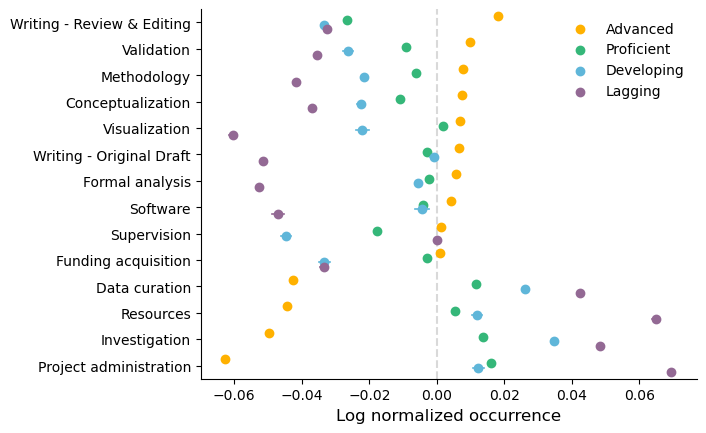

In [36]:
fig, ax = plt.subplots()
ax.axvline(x=0, color='#D9D9D9', linestyle='--',zorder=1)
order = normed_df[normed_df['class']=='Advanced'].groupby(['credit'])['norm'].mean().sort_values(ascending=False).index
sns.pointplot(x="norm", y="credit", data=normed_df, join=False, hue="class", dodge=0.5, errwidth=1.2, scale=0.8, order=order,
             palette=color_dict,
             hue_order=color_dict.keys())

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
legend = ax.legend(frameon=False)
ax.set_xlabel("Log normalized occurrence",fontsize=12)
ax.set_ylabel("")


advanced_means = normed_df[normed_df['class']=='Advanced'].groupby(['credit'])['norm'].mean()
positive_credits = advanced_means[advanced_means>0].index

plt.savefig("../../data/dropbox/LaborDivision/figs/credit_normlized_st_group.pdf",bbox_inches='tight',transparent=True)

In [37]:
ax.get_yticklabels()

[Text(0, 0, 'Writing - Review & Editing'),
 Text(0, 1, 'Validation'),
 Text(0, 2, 'Methodology'),
 Text(0, 3, 'Conceptualization'),
 Text(0, 4, 'Visualization'),
 Text(0, 5, 'Writing - Original Draft'),
 Text(0, 6, 'Formal analysis'),
 Text(0, 7, 'Software'),
 Text(0, 8, 'Supervision'),
 Text(0, 9, 'Funding acquisition'),
 Text(0, 10, 'Data curation'),
 Text(0, 11, 'Resources'),
 Text(0, 12, 'Investigation'),
 Text(0, 13, 'Project administration')]

In [38]:
data_intl['total_tasks'] = data_intl.groupby(['ost_bk'])['credit'].transform('nunique')
author_credit_share = data_intl.groupby(
    ['ost_bk','total_tasks','cluster_id','class'])['credit'].nunique().reset_index(name='count')
author_credit_share['share'] = author_credit_share['count']/author_credit_share['total_tasks']

/tmp/ipykernel_2051841/3299197453.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_intl['total_tasks'] = data_intl.groupby(['ost_bk'])['credit'].transform('nunique')


In [39]:
# Function to perform pairwise t-tests between 'Advanced' and other groups
def perform_t_tests(df, group1, group2):
    advanced_group = df[df['class'].isin(group1)]['share']
    significance_labels = {}
    
    for grp in group2:
        group = df[df['class'] == grp]['share']
        t_stat, p_value = stats.ttest_ind(advanced_group, group, equal_var=False,alternative='greater')
        significance_labels[grp] = p_value_to_label(p_value)
    
    return significance_labels

# Function to convert p-value to significance label
def p_value_to_label(p_value):
    if p_value < 0.001:
        return "***"
    elif p_value < 0.01:
        return "**"
    elif p_value < 0.05:
        return "*"
    elif p_value < 0.1:
        return "+"
    else:
        return "ns"  # not significant

# Function to create the boxplot
def create_boxplot(df, color_dict):
    fig, ax = plt.subplots()
    
    sns.boxplot(
        x='class',
        y='share',
        data=df,
        order=color_dict.keys(),
        boxprops={'facecolor': 'none', 'edgecolor': '#737373'},
        medianprops={'color': '#737373'},
        whiskerprops={'color': '#737373'},
        capprops={'color': '#737373'},
        fliersize=0,
        ax=ax
    )
    
    # Customize plot appearance
    ax.set_ylabel("Share of contributions", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    return fig, ax

# Function to annotate the significance labels on the plot
def annotate_significance(ax, df, group2, significance_labels):
    for ind,grp in enumerate(group2):
        x1,x2 = 0, ind+1
        y = author_credit_share['share'].max()+(ind*0.06)+0.02
        h=0.03
        ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c='k')
        ax.text((x1+x2)*.5, y+h, significance_labels[grp], ha='center', va='bottom', color='k')
    return ax

# Main plotting function, combining everything
def plot(df, color_dict):
    group1 = ['Advanced']
    group2 = ['Proficient', 'Developing', 'Lagging']
    
    # Perform t-tests and get significance labels
    significance_labels = perform_t_tests(df, group1, group2)
    
    # Create the boxplot
    fig, ax = create_boxplot(df, color_dict)
    
    # Annotate the plot with significance labels
    ax = annotate_significance(ax, df, group2,significance_labels)
    
    return fig, ax

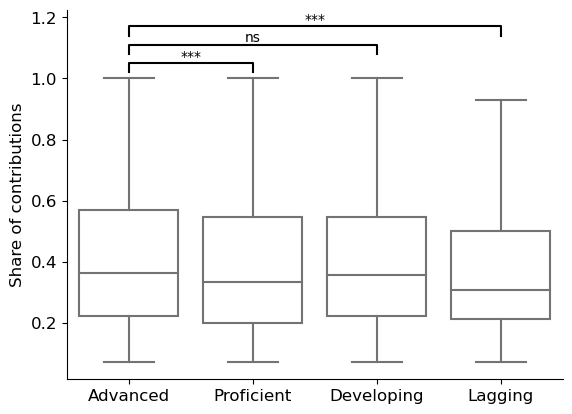

In [40]:
fig, ax = plot(author_credit_share, color_dict)
plt.savefig("../../data/dropbox/LaborDivision/figs/share_of_credit.pdf",bbox_inches='tight')

In [41]:
author_credit = data_intl.groupby(['ost_bk','cluster_id','class'])['credit'].apply(list).reset_index()

In [42]:
# Function to calculate Jaccard similarity
def jaccard_similarity(set1, set2):
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    jaccard = intersection / union if union != 0 else 0
    complement = 1 - jaccard
    return complement

# List to store results
results = []

# Group by 'ost_bk' to process each group separately
for paper_id, group in author_credit.groupby('ost_bk'):
    authors = group['cluster_id'].tolist()
    countries = group['class'].tolist()
    # Convert task lists to sets for each author to optimize the Jaccard calculation
    tasks_sets = [set(tasks) for tasks in group['credit']]
    
    # Get all combinations of authors within the same group
    for (i, j) in combinations(range(len(authors)), 2):
        author_1, author_2 = authors[i], authors[j]
        country_1, country_2 = countries[i], countries[j]
        tasks_1, tasks_2 = tasks_sets[i], tasks_sets[j]
        
        # Calculate Jaccard similarity
        complementary = jaccard_similarity(tasks_1, tasks_2)
        
        # Store the result for both (i, j) and (j, i)
        results.extend([
            {
                'paper_id': paper_id,
                'author_1': author_1,
                'group1': country_1,
                'author_2': author_2,
                'group2': country_2,
                'complementary': complementary
            },
            {
                'paper_id': paper_id,
                'author_1': author_2,
                'group1': country_2,
                'author_2': author_1,
                'group2': country_1,
                'complementary': complementary
            }
        ])

# Create the result DataFrame
result_df = pd.DataFrame(results)

In [43]:
def group_by_group(df):
    df = df.groupby(['group1','group2'])['complementary'].mean().reset_index()
    df = df.pivot(index='group1', columns='group2', values='complementary')
    return df

In [44]:
credit_com = group_by_group(result_df)

In [52]:
def plot(df):
    order = ['Advanced','Proficient','Developing','Lagging']
    df = df[order]
    df = df.reindex(order)
    
    fig, ax = plt.subplots()
    mask = np.tril(np.ones_like(df, dtype=bool),k=-1)
    sns.heatmap(df, cmap='viridis', annot=True, fmt=".2f", mask=mask, ax=ax,
                vmin=np.round(df.min().min(),decimals=2), 
                vmax=np.round(df.max().max(),decimals=2),
               cbar_kws={'label': 'Complementarity Score'})
    
    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_size(12)  # Set font size here (e.g., 14)
    
    ax.xaxis.set_ticks_position('top')  # Move ticks to the top
    ax.xaxis.set_label_position('top')  # Move label to the top

    # Remove minor ticks
    ax.tick_params(axis='x', which='both', bottom=False, top=False)

    # If you want to remove minor ticks for y-axis as well
    ax.tick_params(axis='y', which='both', left=False, right=False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    return fig, ax

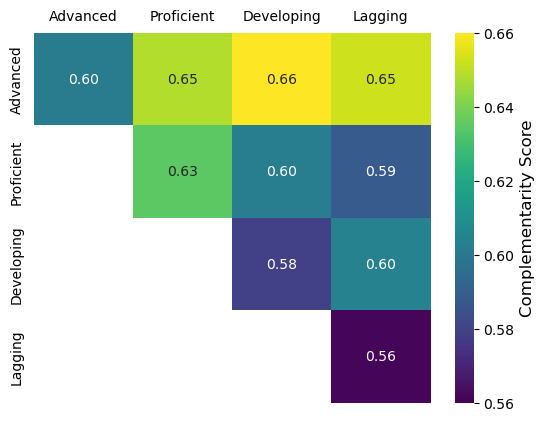

In [53]:
fig, ax = plot(credit_com)
plt.savefig("../../data/dropbox/LaborDivision/figs/credit_complementary.pdf",bbox_inches='tight')

In [47]:
credit_com.mean(axis=0)

group2
Advanced      0.640893
Developing    0.611685
Lagging       0.601417
Proficient    0.618387
dtype: float64